In [1]:
%pip install tensorflow datasets scikit-learn matplotlib pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
#checking version
import sys
print("Python version:", sys.version)

import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
TensorFlow version: 2.22.0-rc0
Available GPUs: []


In [3]:
#load dataset
from datasets import load_dataset
dataset=load_dataset("Project-AgML/tomato_leaf_disease",split="train")
print(dataset)
print(dataset.column_names)

Dataset({
    features: ['image', 'label'],
    num_rows: 11000
})
['image', 'label']


In [4]:
#inspect plant  disease
from collections import Counter

print("Dataset size:", len(dataset))

label_feature = dataset.features["label"]

print("\nLabel names:")
print(label_feature.names)

print("\nImages per class:")
counts = Counter(dataset["label"])

for label_id, count in sorted(counts.items()):
    label_name = label_feature.int2str(label_id)
    print(f"{label_name}: {count}")

Dataset size: 11000

Label names:
['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus']

Images per class:
Bacterial Spot: 1100
Early Blight: 1100
Healthy: 1100
Late Blight: 1100
Leaf Mold: 1100
Septoria Leaf Spot: 1100
Spider Mites Two-spotted Spider Mite: 1100
Target Spot: 1100
Tomato Mosaic Virus: 1100
Tomato Yellow Leaf Curl Virus: 1100


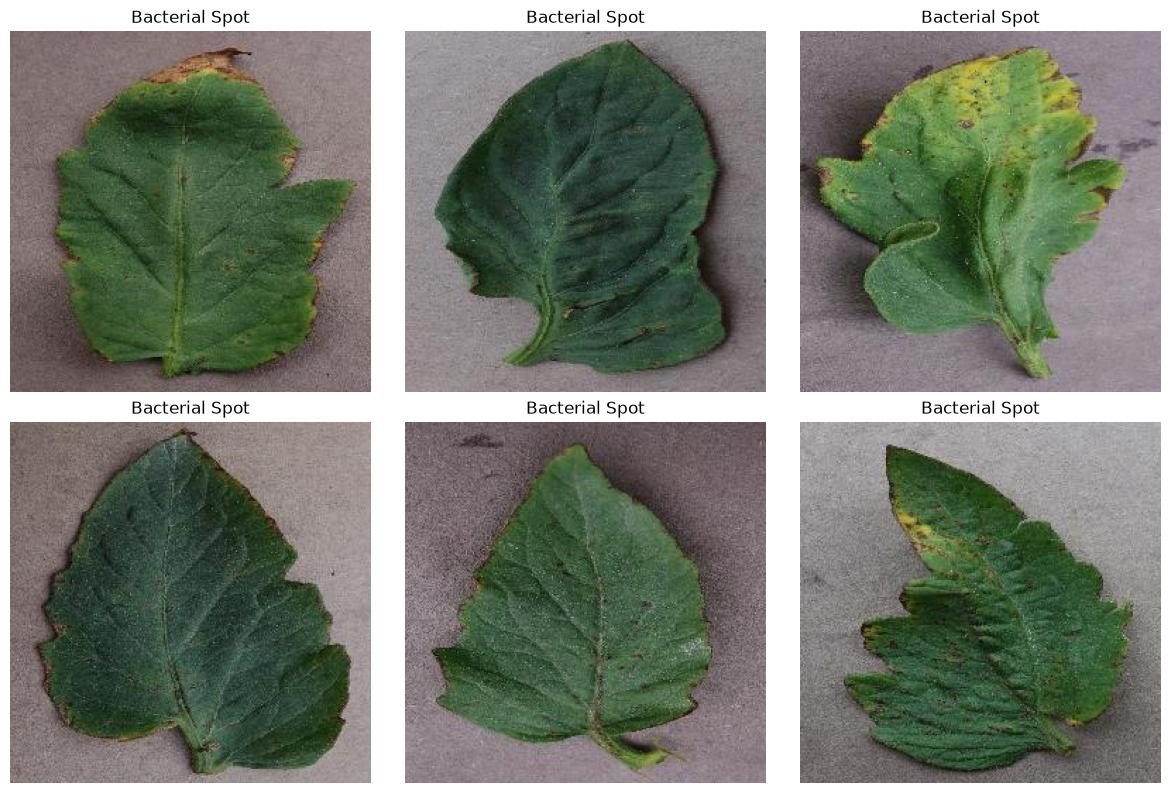

In [5]:
#display sample leaf images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    sample = dataset[i]
    ax.imshow(sample["image"])
    ax.set_title(label_feature.int2str(sample["label"]))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Split into 80% training and 20% temporary data
split_1 = dataset.train_test_split(
    test_size=0.20,
    seed=42,
    stratify_by_column="label"
)

train_data = split_1["train"]
temp_data = split_1["test"]

# Split temporary data equally into validation and test sets
split_2 = temp_data.train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label"
)

val_data = split_2["train"]
test_data = split_2["test"]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Training images: 8800
Validation images: 1100
Testing images: 1100


In [7]:
# Prepare images for the model
import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 16

print("TensorFlow version:", tf.__version__)
print("CPU devices:", tf.config.list_physical_devices("CPU"))

TensorFlow version: 2.22.0-rc0
CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [8]:
from collections import Counter
from PIL import Image

class_names = label_feature.names
NUM_CLASSES = len(class_names)

def prepare_example(example):
    image = example["image"].convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    image = np.array(image, dtype=np.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, int(example["label"])

def make_dataset(hf_dataset, shuffle=False):
    def generator():
        for example in hf_dataset:
            yield prepare_example(example)

    output_signature = (
        tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int64)
    )

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if shuffle:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(1)

train_ds = make_dataset(train_data, shuffle=True)
val_ds = make_dataset(val_data)
test_ds = make_dataset(test_data)

print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)
print("Datasets prepared!")

Number of classes: 10
Classes: ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus']
Datasets prepared!


In [9]:
# Load the pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          12,810 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
# train the models
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_tomato_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3


C:\Users\Gayathri R\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


550/550 ━━━━━━━━━━━━━━━━━━━━ 210s 371ms/step - accuracy: 0.7524 - loss: 0.7952 - val_accuracy: 0.8564 - val_loss: 0.4820
Epoch 2/3
550/550 ━━━━━━━━━━━━━━━━━━━━ 189s 339ms/step - accuracy: 0.8759 - loss: 0.4055 - val_accuracy: 0.8918 - val_loss: 0.3734
Epoch 3/3
550/550 ━━━━━━━━━━━━━━━━━━━━ 180s 323ms/step - accuracy: 0.9045 - loss: 0.3173 - val_accuracy: 0.8882 - val_loss: 0.3378


In [11]:
#check results
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

69/69 ━━━━━━━━━━━━━━━━━━━━ 28s 400ms/step - accuracy: 0.8691 - loss: 0.3838
Test loss: 0.3838
Test accuracy: 86.91%


69/69 ━━━━━━━━━━━━━━━━━━━━ 17s 231ms/step
                                      precision    recall  f1-score   support

                      Bacterial Spot       0.88      0.85      0.86       110
                        Early Blight       0.86      0.63      0.73       110
                             Healthy       0.94      0.96      0.95       110
                         Late Blight       0.82      0.87      0.85       110
                           Leaf Mold       0.87      0.90      0.88       110
                  Septoria Leaf Spot       0.80      0.81      0.81       110
Spider Mites Two-spotted Spider Mite       0.93      0.82      0.87       110
                         Target Spot       0.72      0.91      0.80       110
                 Tomato Mosaic Virus       0.95      0.98      0.96       110
       Tomato Yellow Leaf Curl Virus       0.97      0.96      0.97       110

                            accuracy                           0.87      1100
                    

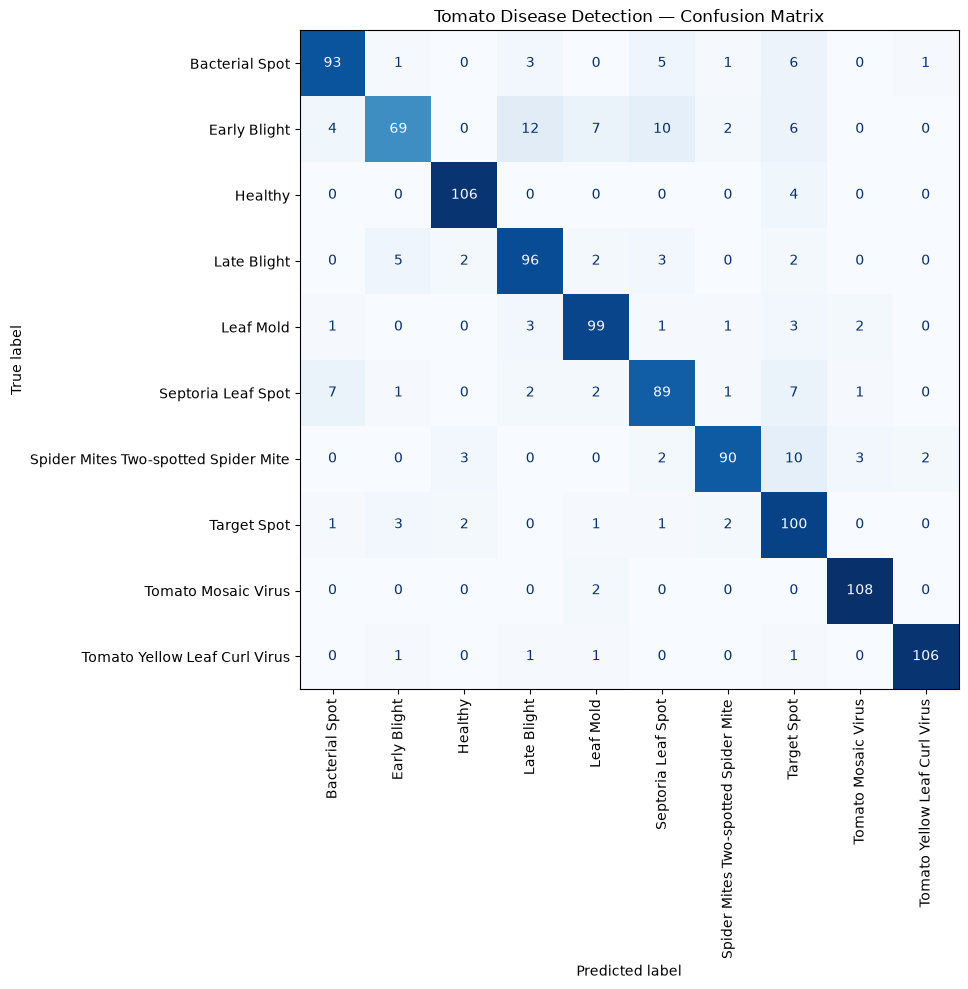

In [12]:
# Generate evaluation metrics
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Get true labels and model predictions
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Print precision, recall, and F1-score
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Tomato Disease Detection — Confusion Matrix")
plt.tight_layout()
plt.show()

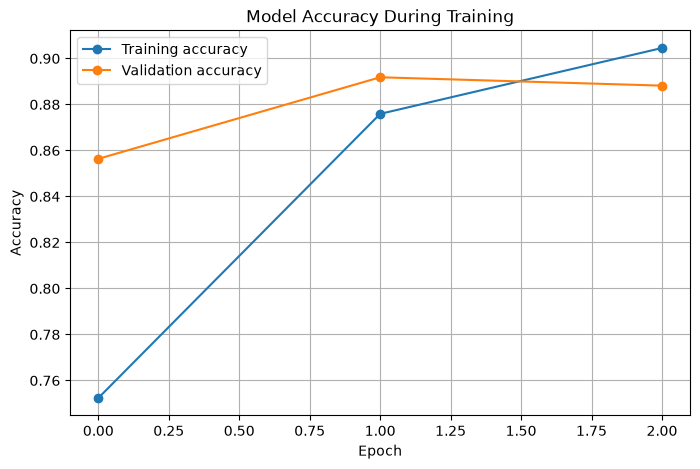

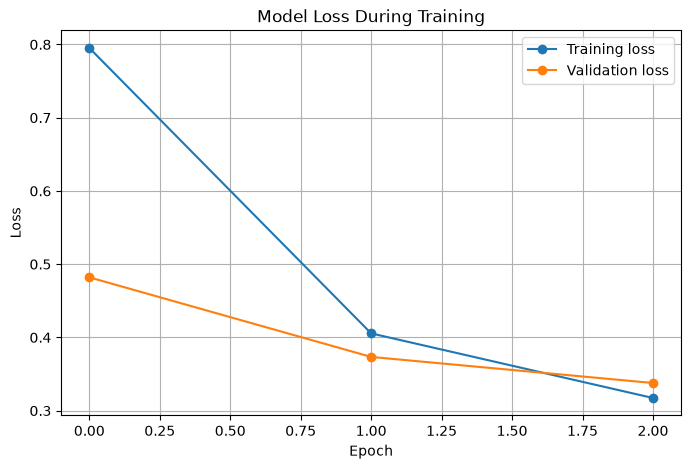

In [13]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy During Training")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss During Training")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Save your trained model
from pathlib import Path

Path("models").mkdir(exist_ok=True)

model.save("models/tomato_disease_model.keras")

with open("models/class_names.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(class_names))

print("Model and class names saved successfully!")

Model and class names saved successfully!


In [15]:
#  explainable ai with grad-cam function
def make_gradcam_heatmap(image_array, model, base_model):
    feature_extractor = tf.keras.Model(
        inputs=base_model.inputs,
        outputs=base_model.get_layer("out_relu").output
    )

    with tf.GradientTape() as tape:
        conv_output = feature_extractor(image_array, training=False)

        # Pass extracted features through the trained classification head
        x = model.layers[2](conv_output)
        x = model.layers[3](x, training=False)
        predictions = model.layers[4](x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(class_index.numpy())

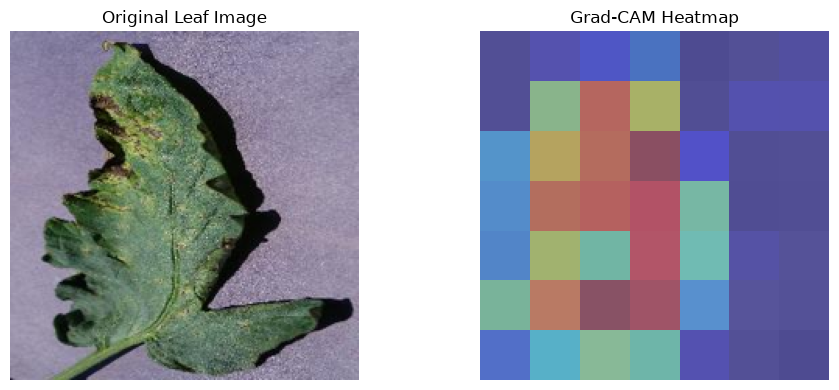

Predicted disease: Septoria Leaf Spot
Confidence score: 80.44%


In [16]:
# visualization
image_batch, label_batch = next(iter(test_ds))
image_array = image_batch[0:1]

heatmap, predicted_index = make_gradcam_heatmap(
    image_array, model, base_model
)

original_image = (image_array[0].numpy() + 1) * 127.5
original_image = np.clip(original_image, 0, 255).astype("uint8")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

probabilities = model.predict(image_array, verbose=0)[0]

print("Predicted disease:", class_names[predicted_index])
print(f"Confidence score: {probabilities[predicted_index]:.2%}")

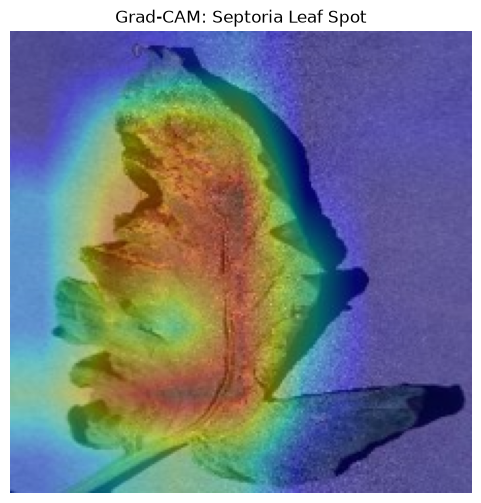

In [17]:
# Improve the Grad-CAM visualization
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Resize heatmap to match the leaf image
heatmap_resized = cv2.resize(
    heatmap,
    (original_image.shape[1], original_image.shape[0])
)

# Display the heatmap over the leaf image
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM: {class_names[predicted_index]}")
plt.axis("off")
plt.show()

In [18]:
# Evaluate individual disease classes
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

                                      precision    recall  f1-score   support

                      Bacterial Spot       0.88      0.85      0.86       110
                        Early Blight       0.86      0.63      0.73       110
                             Healthy       0.94      0.96      0.95       110
                         Late Blight       0.82      0.87      0.85       110
                           Leaf Mold       0.87      0.90      0.88       110
                  Septoria Leaf Spot       0.80      0.81      0.81       110
Spider Mites Two-spotted Spider Mite       0.93      0.82      0.87       110
                         Target Spot       0.72      0.91      0.80       110
                 Tomato Mosaic Virus       0.95      0.98      0.96       110
       Tomato Yellow Leaf Curl Virus       0.97      0.96      0.97       110

                            accuracy                           0.87      1100
                           macro avg       0.87      0.87     

In [19]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

model = tf.keras.models.load_model("best_tomato_model.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [20]:
#get the actual disease class names
print("Number of disease classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of disease classes: 10
0 : Bacterial Spot
1 : Early Blight
2 : Healthy
3 : Late Blight
4 : Leaf Mold
5 : Septoria Leaf Spot
6 : Spider Mites Two-spotted Spider Mite
7 : Target Spot
8 : Tomato Mosaic Virus
9 : Tomato Yellow Leaf Curl Virus


In [21]:
#Create the plant-care recommendation system
plant_care = {
    "Bacterial Spot": {
        "tips": [
            "Avoid working with plants when leaves are wet.",
            "Use clean gardening tools.",
            "Remove severely affected plant debris.",
            "Use disease-free seeds and seedlings."
        ],
        "fertilizer": "Maintain balanced nutrition based on soil testing. Fertilizer does not cure bacterial infection."
    },

    "Early Blight": {
        "tips": [
            "Remove badly affected leaves when practical.",
            "Water near the soil, not over the leaves.",
            "Maintain good airflow between plants.",
            "Remove infected plant debris."
        ],
        "fertilizer": "Maintain balanced nutrition based on soil testing. Avoid unnecessary excess nitrogen."
    },

    "Healthy": {
        "tips": [
            "Inspect leaves regularly.",
            "Water according to soil moisture and weather.",
            "Maintain suitable plant spacing.",
            "Keep the growing area clean."
        ],
        "fertilizer": "Use balanced fertilizer according to soil-test results and the plant's growth stage."
    },

    "Late Blight": {
        "tips": [
            "Inspect nearby plants for similar symptoms.",
            "Reduce prolonged leaf wetness.",
            "Remove confirmed infected material appropriately.",
            "Seek local agricultural advice promptly if symptoms spread."
        ],
        "fertilizer": "Fertilizer cannot cure late blight. Prioritize appropriate disease management."
    },

    "Leaf Mold": {
        "tips": [
            "Improve ventilation around plants.",
            "Avoid excessive humidity where possible.",
            "Water at soil level.",
            "Remove affected plant debris."
        ],
        "fertilizer": "Maintain balanced nutrition according to soil testing; fertilizer does not treat leaf mold."
    },

    "Septoria Leaf Spot": {
        "tips": [
            "Remove severely affected lower leaves when practical.",
            "Avoid splashing soil onto leaves.",
            "Water near the soil.",
            "Remove infected plant debris."
        ],
        "fertilizer": "Use balanced nutrition based on soil testing; fertilizer does not cure leaf spot."
    },

    "Spider Mites Two-spotted Spider Mite": {
        "tips": [
            "Inspect the undersides of leaves for mites and fine webbing.",
            "Monitor plants regularly for increasing damage.",
            "Reduce dust around plants where practical.",
            "Protect beneficial insects and follow locally recommended mite management."
        ],
        "fertilizer": "Fertilizer does not control spider mites. Maintain balanced plant nutrition."
    },

    "Target Spot": {
        "tips": [
            "Improve airflow around plants.",
            "Avoid prolonged leaf wetness.",
            "Remove affected plant debris.",
            "Monitor nearby leaves for new symptoms."
        ],
        "fertilizer": "Maintain balanced nutrition based on soil testing. Fertilizer does not cure target spot."
    },

    "Tomato Mosaic Virus": {
        "tips": [
            "Remove and isolate suspected infected plants while seeking confirmation.",
            "Clean tools and hands after handling affected plants.",
            "Avoid using tobacco products around plants.",
            "Use clean planting material."
        ],
        "fertilizer": "There is no fertilizer cure for viral disease. Maintain appropriate nutrition and follow local disease-management advice."
    },

    "Tomato Yellow Leaf Curl Virus": {
        "tips": [
            "Look for yellowing, curling leaves and stunted growth.",
            "Monitor for whiteflies.",
            "Use clean planting material.",
            "Seek local advice on managing whiteflies and infected plants."
        ],
        "fertilizer": "Fertilizer does not cure viral disease. Use soil-test-based nutrition and appropriate vector management."
    }
}

print("Care recommendations created for", len(plant_care), "classes.")

Care recommendations created for 10 classes.


In [23]:
predicted_disease = "Early Blight"
confidence = 0.92

print("Predicted disease:", predicted_disease)
print("Confidence:", f"{confidence:.2%}")

Predicted disease: Early Blight
Confidence: 92.00%


In [24]:
#Automatically display recommendations
advice = plant_care.get(predicted_disease)

if advice:
    print("🌿 Predicted disease:", predicted_disease)
    print(f"Model confidence: {confidence:.2%}")

    print("\n🌱 Natural care tips:")
    for tip in advice["tips"]:
        print("-", tip)

    print("\n🧪 Nutrient guidance:")
    print(advice["fertilizer"])
else:
    print("No recommendations found for this class.")

🌿 Predicted disease: Early Blight
Model confidence: 92.00%

🌱 Natural care tips:
- Remove badly affected leaves when practical.
- Water near the soil, not over the leaves.
- Maintain good airflow between plants.
- Remove infected plant debris.

🧪 Nutrient guidance:
Maintain balanced nutrition based on soil testing. Avoid unnecessary excess nitrogen.


In [25]:
# Connect it to your actual model
predictions = model.predict(image_array, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_disease = class_names[predicted_index]
confidence = float(predictions[predicted_index])

print("Actual prediction:", predicted_disease)
print(f"Confidence: {confidence:.2%}")

Actual prediction: Septoria Leaf Spot
Confidence: 80.44%


In [26]:
# Display recommendations for your actual prediction
advice = plant_care.get(predicted_disease)

if advice:
    print("🌿 PLANT HEALTH REPORT")
    print("=" * 35)

    print("Predicted Disease:", predicted_disease)
    print(f"Model Confidence: {confidence:.2%}")

    print("\n🌱 NATURAL CARE TIPS")
    for tip in advice["tips"]:
        print("•", tip)

    print("\n🧪 NUTRIENT GUIDANCE")
    print(advice["fertilizer"])

else:
    print("No recommendations available for this disease.")

🌿 PLANT HEALTH REPORT
Predicted Disease: Septoria Leaf Spot
Model Confidence: 80.44%

🌱 NATURAL CARE TIPS
• Remove severely affected lower leaves when practical.
• Avoid splashing soil onto leaves.
• Water near the soil.
• Remove infected plant debris.

🧪 NUTRIENT GUIDANCE
Use balanced nutrition based on soil testing; fertilizer does not cure leaf spot.


In [27]:
# Add a confidence warning
if confidence < 0.70:
    print("\n⚠️ Low confidence.")
    print("Upload a clearer image and verify the symptoms.")
else:
    print("\nNote: This is an AI prediction, not a confirmed diagnosis.")


Note: This is an AI prediction, not a confirmed diagnosis.


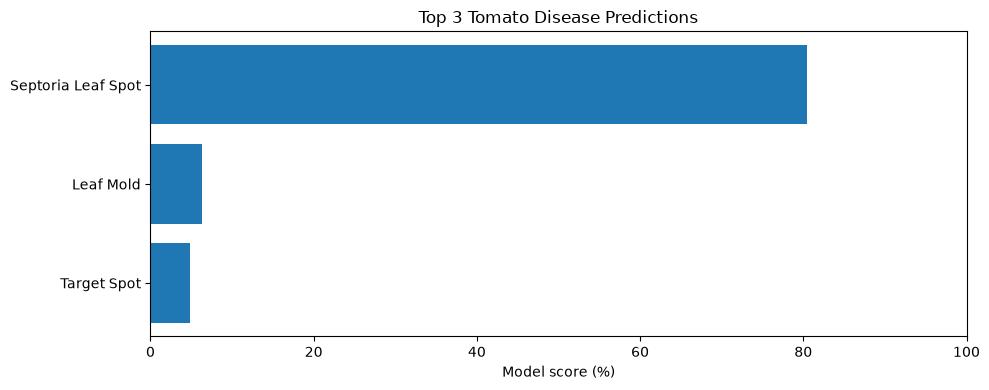

In [28]:
 # Visualize the top 3 predictions
import numpy as np
import matplotlib.pyplot as plt

# Get the top 3 model scores
top_indices = np.argsort(predictions)[-3:][::-1]

labels = [class_names[i] for i in top_indices]
scores = [predictions[i] * 100 for i in top_indices]

# Plot the results
plt.figure(figsize=(10, 4))
plt.barh(labels[::-1], scores[::-1])
plt.xlabel("Model score (%)")
plt.title("Top 3 Tomato Disease Predictions")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()